# Supervised Learning Pipeline — Steel Plates Faults Dataset

**Prerequisite (Foundational)** — evaluation metrics reused in later experiments.

This notebook covers:
1. Loading a less-common real-world dataset from the UCI Machine Learning Repository
2. Basic data inspection and cleaning
3. Train–test split
4. Feature scaling
5. Training a Random Forest classifier
6. Evaluation using accuracy, precision, recall, F1-score, classification report, and confusion matrix

**Dataset:** Steel Plates Faults. It contains 1,941 steel-plate observations, 27 numerical features, and 7 fault classes. The task is to classify the type of fault detected on a steel plate.

## 1. Imports

In [1]:
!pip -q install ucimlrepo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

pd.set_option('display.max_columns', 50)
RANDOM_STATE = 42


## 2. Download and Load the Dataset

In [2]:
# Steel Plates Faults — UCI dataset (ID 198)
steel_plates = fetch_ucirepo(id=198)

X = steel_plates.data.features.copy()
y = steel_plates.data.targets.copy()

print('Feature shape:', X.shape)
print('Target shape:', y.shape)
print('\nFeature columns:')
print(X.columns.tolist())

df = pd.concat([X, y], axis=1)
df.head()


Feature shape: (1941, 27)
Target shape: (1941, 7)

Feature columns:
['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness', 'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index', 'SigmoidOfAreas', 'Minimum_of_Luminosity']


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Minimum_of_Luminosity,Pastry,Z_Scratch,K_Scratch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,108,1687,1,0,80,0.0498,0.2415,0.1818,0.0047,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,76,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,123,1687,1,0,80,0.7647,0.3793,0.2069,0.0036,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,84,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,125,1623,1,0,100,0.9710,0.3426,0.3333,0.0037,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,99,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,126,1353,0,1,290,0.7287,0.4413,0.1556,0.0052,0.5385,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,99,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,126,1353,0,1,185,0.0695,0.4486,0.0662,0.0126,0.2833,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000,37,1,0,0,0,0,0,0


## 3. Quick Data Overview

In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1941 entries, 0 to 1940
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   X_Minimum              1941 non-null   int64  
 1   X_Maximum              1941 non-null   int64  
 2   Y_Minimum              1941 non-null   int64  
 3   Y_Maximum              1941 non-null   int64  
 4   Pixels_Areas           1941 non-null   int64  
 5   X_Perimeter            1941 non-null   int64  
 6   Y_Perimeter            1941 non-null   int64  
 7   Sum_of_Luminosity      1941 non-null   int64  
 8   Maximum_of_Luminosity  1941 non-null   int64  
 9   Length_of_Conveyer     1941 non-null   int64  
 10  TypeOfSteel_A300       1941 non-null   int64  
 11  TypeOfSteel_A400       1941 non-null   int64  
 12  Steel_Plate_Thickness  1941 non-null   int64  
 13  Edges_Index            1941 non-null   float64
 14  Empty_Index            1941 non-null   float64
 15  Squa

In [4]:
print('Missing values per column:\n')
print(df.isnull().sum())

print('\nDuplicate rows:', df.duplicated().sum())


Missing values per column:

X_Minimum                0
X_Maximum                0
Y_Minimum                0
Y_Maximum                0
Pixels_Areas             0
X_Perimeter              0
Y_Perimeter              0
Sum_of_Luminosity        0
Maximum_of_Luminosity    0
Length_of_Conveyer       0
TypeOfSteel_A300         0
TypeOfSteel_A400         0
Steel_Plate_Thickness    0
Edges_Index              0
Empty_Index              0
Square_Index             0
Outside_X_Index          0
Edges_X_Index            0
Edges_Y_Index            0
Outside_Global_Index     0
LogOfAreas               0
Log_X_Index              0
Log_Y_Index              0
Orientation_Index        0
Luminosity_Index         0
SigmoidOfAreas           0
Minimum_of_Luminosity    0
Pastry                   0
Z_Scratch                0
K_Scratch                0
Stains                   0
Dirtiness                0
Bumps                    0
Other_Faults             0
dtype: int64

Duplicate rows: 0


## 4. Identify Target Column

The UCI dataset provides the fault type as the target. The seven classes are:
- Pastry
- Z_Scratch
- K_Scatch
- Stains
- Dirtiness
- Bumps
- Other_Faults

In [5]:
target_col = y.columns[0]
print('Target column:', target_col)
print('\nClass distribution:')
print(y[target_col].value_counts())


Target column: Pastry

Class distribution:
Pastry
0    1783
1     158
Name: count, dtype: int64


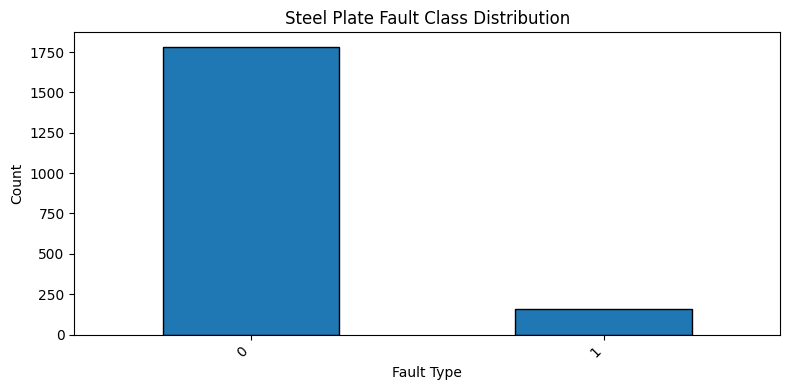

In [6]:
plt.figure(figsize=(8, 4))
y[target_col].value_counts().plot(kind='bar', edgecolor='black')
plt.title('Steel Plate Fault Class Distribution')
plt.xlabel('Fault Type')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## 5. Data Cleaning

In [7]:
# The UCI documentation reports no missing values.
# We still perform a defensive numeric conversion and check for missing values.
feature_cols = X.columns.tolist()

X = X.apply(pd.to_numeric, errors='coerce')

print('Missing feature values:', X.isnull().sum().sum())
print('Missing target values:', y[target_col].isnull().sum())


Missing feature values: 0
Missing target values: 0


## 6. Train–Test Split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y[target_col],
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y[target_col]
)

print('Train shape:', X_train.shape)
print('Test shape:', X_test.shape)


Train shape: (1552, 27)
Test shape: (389, 27)


## 7. Feature Scaling

In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Scaled training matrix shape:', X_train_scaled.shape)
print('Scaled test matrix shape:', X_test_scaled.shape)


Scaled training matrix shape: (1552, 27)
Scaled test matrix shape: (389, 27)


## 8. Train a Random Forest Classifier

In [10]:
clf = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

clf.fit(X_train_scaled, y_train)
y_pred = clf.predict(X_test_scaled)

print('Model training completed.')


Model training completed.


## 9. Evaluation Metrics

In [11]:
# Weighted averages account for the unequal number of observations in each fault class.
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print(f'Accuracy:  {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall:    {recall:.4f}')
print(f'F1-score:  {f1:.4f}')


Accuracy:  0.9409
Precision: 0.9345
Recall:    0.9409
F1-score:  0.9309


In [12]:
print('Full classification report:\n')
print(classification_report(y_test, y_pred, zero_division=0))


Full classification report:

              precision    recall  f1-score   support

           0       0.95      0.99      0.97       357
           1       0.80      0.38      0.51        32

    accuracy                           0.94       389
   macro avg       0.87      0.68      0.74       389
weighted avg       0.93      0.94      0.93       389



## 10. Confusion Matrix

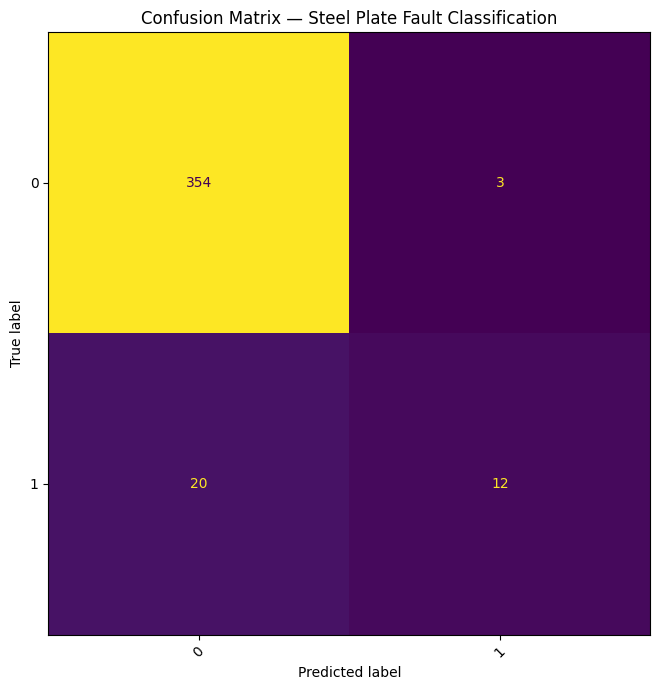

In [13]:
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf.classes_)
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title('Confusion Matrix — Steel Plate Fault Classification')
plt.tight_layout()
plt.show()


## 11. Feature Importance

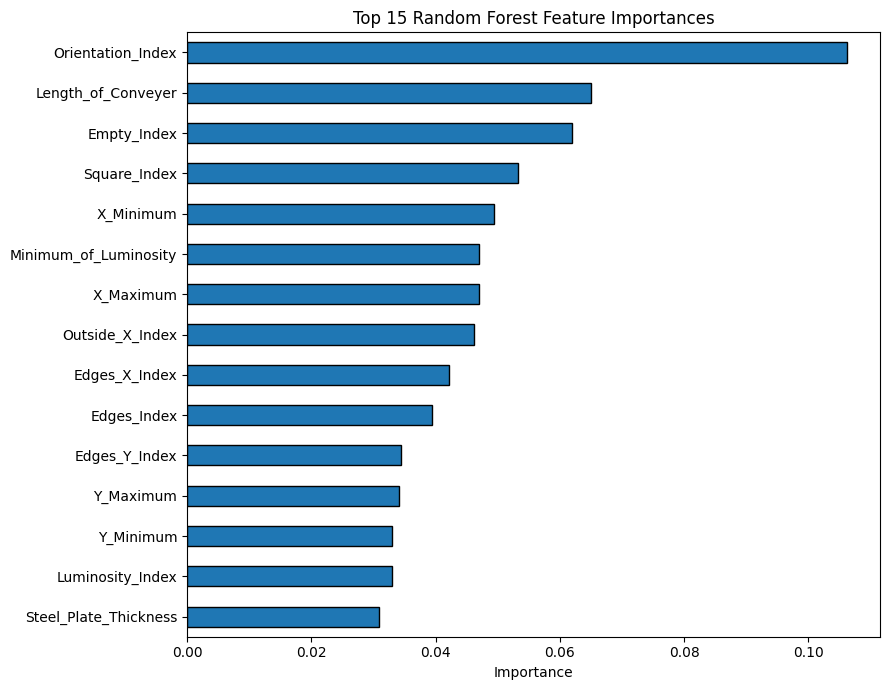

Top 15 features:
Orientation_Index        0.106212
Length_of_Conveyer       0.065063
Empty_Index              0.061999
Square_Index             0.053333
X_Minimum                0.049353
Minimum_of_Luminosity    0.047016
X_Maximum                0.046986
Outside_X_Index          0.046174
Edges_X_Index            0.042076
Edges_Index              0.039355
Edges_Y_Index            0.034380
Y_Maximum                0.034082
Y_Minimum                0.032942
Luminosity_Index         0.032907
Steel_Plate_Thickness    0.030826
dtype: float64


In [14]:
importance = pd.Series(clf.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(9, 7))
importance.head(15).sort_values().plot(kind='barh', edgecolor='black')
plt.title('Top 15 Random Forest Feature Importances')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print('Top 15 features:')
print(importance.head(15))


## 12. Conclusion

- The Steel Plates Faults dataset provides a less commonly used supervised-learning classification problem than standard classroom datasets such as Iris, Titanic, or Wine.
- A Random Forest classifier was trained using the 27 numerical measurements describing each steel plate fault.
- Accuracy, weighted precision, weighted recall, and weighted F1-score are reported because this is a seven-class problem with unequal class frequencies.
- The confusion matrix shows which fault categories are most frequently confused by the classifier.
- Feature importance provides an additional view of which measured characteristics contribute most to the Random Forest's decisions.

### Dataset Source

Buscema, M., Terzi, S., & Tastle, W. (2010). **Steel Plates Faults**. UCI Machine Learning Repository, dataset ID 198.

The UCI repository describes the dataset as 1,941 instances with 27 features and seven steel-plate fault classes.